# OGM: convergence and Lyapunov discovery

Let $f$ be convex and $L$-smooth on a real finite-dimensional Euclidean space, with $L>0$, $R\geq0$, $N\geq1$, $\nabla f(x_\star)=0$, $\|x_0-x_\star\|^2\leq R^2$, and $z_0=x_0$. The metric is $f(x_N)-f(x_\star)$.

Set $\theta_{-1}=0$ and
$$\theta_k=\frac{1+\sqrt{1+4\theta_{k-1}^2}}2\quad(0\leq k<N),\qquad
\theta_N=\frac{1+\sqrt{1+8\theta_{N-1}^2}}2.$$
For $0\leq k<N$,
$$y_{k+1}=x_k-\frac{\nabla f(x_k)}L,\qquad
z_{k+1}=z_k-\frac{2\theta_k}L\nabla f(x_k),$$
$$x_{k+1}=\left(1-\frac1{\theta_{k+1}}\right)y_{k+1}+\frac{z_{k+1}}{\theta_{k+1}}.$$
The terminal recurrence is distinct and is retained in every numerical problem.


## Proof Statement

### Theorem
Under the smooth-convex assumptions and the algorithm stated above, the following potential is nonincreasing for every integer $N\geq1$, every $L>0$, and every $R\geq0$.
Write $g_{k}=\nabla f(x_{k})$, $T=\theta_{N}$, and
$$\rho_{k}=\begin{cases}\theta_{k},&0\leq k<N,\\ T/2,&k=N.\end{cases}$$
For $0\leq k\leq N$, define
$$V_{k}=\frac{L}{2T^{2}}\bigl(\|z_{k}-x_{\star}\|^{2}-\|x_{0}-x_{\star}\|^{2}\bigr)
+\frac{2\theta_{k-1}^{2}}{T^{2}}(f(x_{k})-f(x_{\star}))
+\frac{\theta_{k-1}^{2}}{LT^{2}}\|g_{k}\|^{2}
+\frac{2\rho_{k}}{T^{2}}\langle g_{k},x_{k}-z_{k}\rangle.$$
Here $\theta_{-1}=0$, so $V_{0}=0$. The terminal coefficient uses $\rho_{N}=T/2$.

The terminal identity implies the finite-horizon bound
$$\boxed{f(x_{N})-f(x_{\star})\leq\frac{L R^{2}}{2\theta_{N}^{2}}.}$$
The claim is an upper bound; no separate arbitrary-horizon tightness construction is asserted.


### Proof outline
Write $g_{k}=\nabla f(x_{k})$, $T=\theta_{N}$, and
$$\rho_{k}=\begin{cases}\theta_{k},&0\leq k<N,\\ T/2,&k=N.\end{cases}$$
For $0\leq k\leq N$, define
$$V_{k}=\frac{L}{2T^{2}}\bigl(\|z_{k}-x_{\star}\|^{2}-\|x_{0}-x_{\star}\|^{2}\bigr)
+\frac{2\theta_{k-1}^{2}}{T^{2}}(f(x_{k})-f(x_{\star}))
+\frac{\theta_{k-1}^{2}}{LT^{2}}\|g_{k}\|^{2}
+\frac{2\rho_{k}}{T^{2}}\langle g_{k},x_{k}-z_{k}\rangle.$$
Here $\theta_{-1}=0$, so $V_{0}=0$. The terminal coefficient uses $\rho_{N}=T/2$.

Define the nonpositive interpolation residual
$$I_{i,j}=f(x_{j})-f(x_{i})+\langle g_{j},x_{i}-x_{j}\rangle+\frac{\|g_{i}-g_{j}\|^{2}}{2L}\leq0,$$
including $x_{\star}$ with $g_{\star}=0$.
The exact recursion, including the final update, is
$$V_{k+1}-V_{k}=\frac{2\theta_{k}}{T^{2}}I_{\star,k}+\frac{2\theta_{k}^{2}}{T^{2}}I_{k,k+1}\leq0\qquad(0\leq k<N).$$
Both multipliers are positive. Thus $V_{N}\leq V_{0}=0$. The terminal relation is
$$f(x_{N})-f(x_{\star})-\frac{L}{2T^{2}}\|x_{0}-x_{\star}\|^{2}
=V_{N}+\frac{I_{\star,N}}{T}-\frac{L}{2T^{2}}\left\|z_{N}-x_{\star}-\frac{T}{L}g_{N}\right\|^{2}\leq0.$$
The initial radius bound gives the stated result. Separate exact checks below cover the generic step, the base step, the terminal identity, normalization, and $N=1$.


In [1]:
import json
import sys
from pathlib import Path

notebook_dir = Path.cwd()
repo_root = notebook_dir / "supplementary" / "approved"
sys.path[:0] = [str(repo_root), str(notebook_dir), str(notebook_dir / "supplementary")]
import matplotlib.pyplot as plt  # noqa: E402

## Function, algorithm, and PEP definition
The code below is the executable setup, including the radius squared normalization.

In [2]:
import math

import pepflow as pf

L = pf.Parameter("L")
R = pf.Parameter("R")
f = pf.SmoothConvexFunction(is_basis=True, tags=["f"], L=L)


def theta_sequence(N):
    """Return theta_0,...,theta_N in double precision for numerical PEPs."""
    theta = []
    previous = 0.0
    for k in range(int(N) + 1):
        previous = (1 + math.sqrt(1 + (8 if k == N else 4) * previous**2)) / 2
        theta.append(previous)
    return theta


def make_ctx_ogm(ctx_name: str, N, **kwargs) -> pf.PEPContext:
    ctx = pf.PEPContext(ctx_name).set_as_current()
    x = pf.Vector(is_basis=True, tags=["x_0"])
    f.set_stationary_point("x_star")
    z = x
    z.add_tag("z_0")
    theta = theta_sequence(N)
    for k in range(int(N)):
        g = f.grad(x)
        y = x - g / L
        y.add_tag(f"y_{k + 1}")
        z = z - (2 * theta[k] / L) * g
        z.add_tag(f"z_{k + 1}")
        x = (1 - 1 / theta[k + 1]) * y + z / theta[k + 1]
        x.add_tag(f"x_{k + 1}")
    return ctx


def get_pep_setup(N, params):
    ctx = make_ctx_ogm(f"ctx_{N}", N)
    pb = pf.PEPBuilder(ctx)
    pb.add_initial_constraint(
        ((ctx["x_0"] - ctx["x_star"]) ** 2).le(R**2, name="initial_condition")
    )
    pb.set_performance_metric(f(ctx[f"x_{N}"]) - f(ctx["x_star"]))
    return ctx, pb, f

## Numerical evidence
The saved sweep used CLARABEL defaults at each horizon. All seven solves were optimal.

N=1: PEP=0.1249999997, candidate=0.1250000000, error=3.249e-10
N=2: PEP=0.0618941831, candidate=0.0618941824, error=6.990e-10
N=3: PEP=0.0376923986, candidate=0.0376923972, error=1.379e-09
N=4: PEP=0.0255839452, candidate=0.0255839420, error=3.117e-09
N=5: PEP=0.0185881398, candidate=0.0185881367, error=3.088e-09
N=6: PEP=0.0141559673, candidate=0.0141559659, error=1.459e-09
N=7: PEP=0.0111604195, candidate=0.0111604169, error=2.624e-09
All solver statuses: ['optimal', 'optimal', 'optimal', 'optimal', 'optimal', 'optimal', 'optimal']


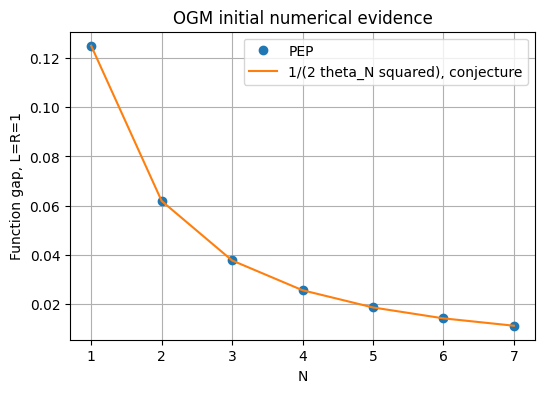

In [3]:
sweep = json.loads((notebook_dir / "supplementary" / "b1_sweep.json").read_text())
horizons = [row["N"] for row in sweep]
observed = [row["opt_value"] for row in sweep]
candidate = [1 / (2 * theta_sequence(n)[-1] ** 2) for n in horizons]
for row, guess in zip(sweep, candidate):
    print(
        f"N={row['N']}: PEP={row['opt_value']:.10f}, candidate={guess:.10f}, error={abs(row['opt_value'] - guess):.3e}"
    )
print("All solver statuses:", [r["solve_attempts"][-1]["status"] for r in sweep])
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(horizons, observed, "o", label="PEP")
ax.plot(horizons, candidate, "-", label="1/(2 theta_N squared), conjecture")
ax.set(xlabel="N", ylabel="Function gap, L=R=1", title="OGM initial numerical evidence")
ax.legend()
ax.grid(True)
plt.show()

The B1 observations suggested
$$f(x_N)-f(x_\star)\leq \frac{LR^2}{2\theta_N^2}.$$
Scaling by $LR^2$ follows by normalizing the function and the initial distance (with $R=0$ trivial). Numerical agreement does not prove the bound. The subsequent sections record the certificate and Lyapunov proof that establish it.



## Dense and relaxed proof solves
The initial dense solve suggested optimal-point and consecutive-pair support. Removing the small reverse terminal pair also preserves the optimum. All selected arrays and multipliers below belong to one primal CLARABEL solve. The displayed code makes the solve and complete certificate reconstruction explicit; saved results avoid repeating an unchanged solve.

In [4]:
import hashlib
import json
import uuid

import cvxpy as cp
import numpy as np
import pepflow as pf
import sympy as sp


def solve_certificate(n, relaxed=()):
    ctx, pb, obj = get_pep_setup(n, {"L": 1, "R": 1})
    all_constraints = [*pb.init_conditions, *obj.get_interpolation_constraints(ctx)]
    pb.set_relaxed_constraints(list(relaxed))
    assert pb.performance_metric is not None
    solver = pf.CVXPrimalSolver(
        pb.performance_metric,
        [c for c in all_constraints if c.name not in relaxed],
        ctx,
    )
    problem = solver.build_problem(
        resolve_parameters={"L": sp.Integer(1), "R": sp.Integer(1)}
    )
    attempts = []
    try:
        value = problem.solve(solver="CLARABEL")
        attempts.append(
            {"solver": "CLARABEL", "settings": {}, "status": problem.status}
        )
    except cp.SolverError as error:
        attempts.append({"solver": "CLARABEL", "settings": {}, "error": str(error)})
        value = None
    if problem.status != "optimal":
        value = problem.solve(solver="SCS", eps=1e-7, max_iters=200000)
        attempts.append(
            {
                "solver": "SCS",
                "settings": {"eps": 1e-7, "max_iters": 200000},
                "status": problem.status,
            }
        )
    assert problem.status == "optimal" and value is not None, attempts
    result = pf.PEPResult(
        value, solver.dual_var_manager, pf.PEPType.PRIMAL, problem.status, ctx
    )
    groups = ctx.get_constraint_data(obj)
    group_names = {
        c.name: str(group)
        for group, constraints in groups.sc_dict.items()
        for c in constraints
    }
    meta, duals = {}, {}
    for c in all_constraints:
        initial = c in pb.init_conditions
        assert isinstance(c, pf.ScalarConstraint)
        meta[c.name] = dict(
            origin="initial" if initial else "interpolation",
            owner=None if initial else str(obj),
            group=group_names.get(c.name),
            kind="scalar",
            comparator=c.cmp.value,
            shape=[],
            relaxed=c.name in relaxed,
        )
        dual = result.get_dual_value(c.name)
        if c.name in relaxed:
            duals[c.name] = None
        else:
            assert dual is not None
            duals[c.name] = float(dual)
    matrix = result.get_gram_dual_matrix()
    lamb = result.get_scalar_constraint_dual_value_in_numpy(obj)
    assert not isinstance(lamb, dict)
    data = dict(
        N=n,
        N_verify=n,
        opt_value=float(value),
        tau_sol=duals["initial_condition"],
        tau_name="initial_condition",
        relaxed_constraints=list(relaxed),
        S_matrix=np.asarray(matrix.matrix, dtype=float).tolist(),
        S_row_names=matrix.row_names,
        S_col_names=matrix.col_names,
        basis_vectors=[str(v) for v in ctx.basis_vectors()],
        basis_scalars=[str(v) for v in ctx.basis_scalars()],
        named_dual_values=duals,
        constraint_metadata=meta,
        solver_attempts=attempts,
        lambda_matrix=np.asarray(lamb.matrix, dtype=float).tolist(),
        lambda_row_names=lamb.row_names,
        lambda_col_names=lamb.col_names,
        certificate_provenance=dict(
            solve_id=str(uuid.uuid4()),
            pep_type="primal",
            solver_status=problem.status,
            solver=dict(
                api="CVXPrimalSolver.build_problem",
                cvxpy_version=cp.__version__,
                effective_name=problem.solver_stats.solver_name,
                settings={},
            ),
        ),
    )
    return data


def revalidate(data):
    ctx, pb, obj = get_pep_setup(data["N"], {"L": 1, "R": 1})
    all_constraints = [*pb.init_conditions, *obj.get_interpolation_constraints(ctx)]
    assert [str(v) for v in ctx.basis_vectors()] == data["basis_vectors"]
    assert [str(v) for v in ctx.basis_scalars()] == data["basis_scalars"]
    assert (
        {c.name for c in all_constraints}
        == set(data["named_dual_values"])
        == set(data["constraint_metadata"])
    )
    pm = pf.ExpressionManager(
        ctx, resolve_parameters={"L": sp.Integer(1), "R": sp.Integer(1)}
    )
    weighted = pf.Scalar.zero()
    for c in all_constraints:
        assert c.cmp.value == data["constraint_metadata"][c.name]["comparator"]
        value = data["named_dual_values"][c.name]
        if c.name in data["relaxed_constraints"]:
            assert value is None
            continue
        assert value is not None and np.isfinite(value)
        residual = c.lhs - c.rhs
        if c.cmp == pf.Comparator.GE:
            residual = -residual
        weighted += value * residual
    basis = ctx.basis_vectors()
    matrix = np.asarray(data["S_matrix"], dtype=float)
    scalar = sum(
        (
            float(matrix[i, j]) * basis[i] * basis[j]
            for i, j in np.ndindex(matrix.shape)
        ),
        pf.Scalar.zero(),
    )
    assert pb.performance_metric is not None
    checked = pm.eval_scalar(
        pb.performance_metric - data["opt_value"] - weighted + scalar
    )
    residuals = dict(
        identity_gram_max_abs=float(
            np.max(np.abs(checked.inner_prod_coords), initial=0)
        ),
        identity_func_max_abs=float(np.max(np.abs(checked.func_coords), initial=0)),
        identity_offset_abs=float(abs(checked.offset)),
        minimum_S_eigenvalue=float(np.linalg.eigvalsh(matrix).min()),
        minimum_scalar_inequality_dual=min(
            v for v in data["named_dual_values"].values() if v is not None
        ),
        minimum_matrix_inequality_eigenvalue=0.0,
    )
    assert all(
        residuals[key] <= 1e-5
        for key in (
            "identity_gram_max_abs",
            "identity_func_max_abs",
            "identity_offset_abs",
        )
    ), residuals
    assert (
        residuals["minimum_S_eigenvalue"] >= -1e-6
        and residuals["minimum_scalar_inequality_dual"] >= -1e-6
    ), residuals
    return ctx, pb, obj, pm, checked, residuals


def certificate_digest(data):
    keys = (
        "N_verify",
        "params_json",
        "relaxed_constraints",
        "S_matrix",
        "S_row_names",
        "S_col_names",
        "basis_vectors",
        "basis_scalars",
        "opt_value",
        "tau_sol",
        "tau_name",
        "named_dual_values",
        "constraint_metadata",
        "normalization",
        "certificate_provenance",
        "numerical_checks",
        "numerical_decomposition",
    )
    return hashlib.sha256(
        json.dumps(
            {key: data[key] for key in keys},
            sort_keys=True,
            separators=(",", ":"),
            allow_nan=False,
        ).encode()
    ).hexdigest()

In [5]:
dense = json.loads((notebook_dir / "state" / "ogm_dense.json").read_text())
certificate = json.loads((notebook_dir / "state" / "ogm_b2.json").read_text())
print("Dense optimum:", dense["opt_value"])
print("Selected optimum:", certificate["opt_value"])
print("Basis:", certificate["basis_vectors"])
print("Dense S eigenvalues:", np.linalg.eigvalsh(dense["S_matrix"]))
print("Removed constraints:", certificate["relaxed_constraints"])
print("Preserved gap:", abs(dense["opt_value"] - certificate["opt_value"]))
for name, value in certificate["named_dual_values"].items():
    if value is not None:
        print(name, value)
assert certificate_digest(certificate) == certificate["certificate_id"]

Dense optimum: 0.025583945166769366
Selected optimum: 0.02558394201140301
Basis: ['z_0', 'x_star', 'grad_f(z_0)', 'grad_f(x_1)', 'grad_f(x_2)', 'grad_f(x_3)', 'grad_f(x_4)']
Dense S eigenvalues: [4.43037711e-10 2.01474034e-09 2.83740725e-09 6.02787447e-09
 1.38597835e-08 3.94637036e-08 2.18759661e+00]
Removed constraints: ['f:z_0,x_star', 'f:z_0,x_2', 'f:z_0,x_3', 'f:z_0,x_4', 'f:x_1,x_star', 'f:x_1,z_0', 'f:x_1,x_3', 'f:x_1,x_4', 'f:x_2,x_star', 'f:x_2,z_0', 'f:x_2,x_1', 'f:x_2,x_4', 'f:x_3,x_star', 'f:x_3,z_0', 'f:x_3,x_1', 'f:x_3,x_2', 'f:x_4,x_star', 'f:x_4,z_0', 'f:x_4,x_1', 'f:x_4,x_2', 'f:x_4,x_3']
Preserved gap: 3.1553663570882406e-09
initial_condition 0.025583942102815994
f:x_star,z_0 0.10233576842211013
f:x_star,x_1 0.16558275132843417
f:x_star,x_2 0.22447627951908947
f:x_star,x_3 0.28140200905783536
f:x_star,x_4 0.2262031920335532
f:z_0,x_1 0.10233576842240312
f:x_1,x_2 0.2679185196742483
f:x_2,x_3 0.4923947991252491
f:x_3,x_4 0.7737968081214347


## Initial formulas and numerical decomposition
The coefficients suggest $\lambda_{\star,k}=2\theta_k/\theta_N^2$ for $k<N$, $\lambda_{\star,N}=1/\theta_N$, and $\lambda_{k,k+1}=2\theta_k^2/\theta_N^2$; all other interpolation multipliers vanish. The initial multiplier is $L/(2\theta_N^2)$.

The rank-one candidate is
$$S_{\mathrm{guess}}=\frac{L}{2\theta_N^2}\left\|z_N-x_\star-\frac{\theta_N}{L}\nabla f(x_N)\right\|^2.$$
At the B2 discovery stage these were numerical candidates. The actual certificate retains the full spectral decomposition, including every small eigenvalue. The later B5 section proves their analytic validity; this section preserves the original numerical comparison.


In [6]:
ctx, pb, obj, pm, checked, checks = revalidate(certificate)
S = np.asarray(certificate["S_matrix"])
print("Selected numerical S matrix:")
pf.pprint_labeled_matrix(
    pf.MatrixWithNames(S, certificate["S_row_names"], certificate["S_col_names"])
)
D = np.asarray(certificate["numerical_decomposition"]["D"])
E = np.asarray(certificate["numerical_decomposition"]["ell_coords"])
assert np.allclose(E.T @ D @ E, S, atol=1e-4, rtol=1e-5)
print("Retained spectral coefficients:", np.diag(D))
print("S reconstruction error:", np.max(np.abs(E.T @ D @ E - S)))
theta = theta_sequence(certificate["N"])
N = certificate["N"]
candidate_lambda = np.zeros_like(certificate["lambda_matrix"], dtype=float)
labels = certificate["lambda_row_names"]
for k in range(N + 1):
    tag = "z_0" if k == 0 else f"x_{k}"
    candidate_lambda[labels.index("x_star"), labels.index(tag)] = (
        1 / theta[N] if k == N else 2 * theta[k] / theta[N] ** 2
    )
    if k < N:
        candidate_lambda[labels.index(tag), labels.index(f"x_{k + 1}")] = (
            2 * theta[k] ** 2 / theta[N] ** 2
        )
assert np.allclose(candidate_lambda, certificate["lambda_matrix"], atol=1e-4, rtol=0)
pf.pprint_labeled_matrix(pf.MatrixWithNames(candidate_lambda, labels, labels))
q = ctx[f"z_{N}"] - ctx["x_star"] - theta[N] * obj.grad(ctx[f"x_{N}"])
S_guess_scalar = pm.eval_scalar(q**2 / (2 * theta[N] ** 2))
assert np.allclose(S_guess_scalar.inner_prod_coords, S, atol=1e-4, rtol=0)
assert np.allclose(S_guess_scalar.func_coords, 0, atol=1e-4, rtol=0)
assert abs(S_guess_scalar.offset) < 1e-4
pf.pprint_labeled_matrix(
    pf.MatrixWithNames(
        S_guess_scalar.inner_prod_coords,
        certificate["S_row_names"],
        certificate["S_col_names"],
    )
)
print("Initial search:", certificate["closed_form_search"])

Selected numerical S matrix:


<IPython.core.display.Math object>

Retained spectral coefficients: [9.77129401e-12 7.14079466e-11 9.10559427e-11 1.61675374e-10
 2.19394545e-10 6.69759949e-10 2.18761378e+00]
S reconstruction error: 7.771561172376096e-16


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Initial search: {'completed': True, 'references_reviewed': ['Own B1 setup and dense/sparse certificates only; external examples excluded by clean-room policy'], 'attempts': [{'method': 'Compare star multipliers to 2 theta_k/theta_N^2 and terminal 1/theta_N; consecutive multipliers to 2 theta_k^2/theta_N^2', 'max_error': 3.6926295354788863e-10}, {'method': 'Inspect rank-one S and compare squared z_N-x_star-theta_N grad f(x_N)/L with coefficient L/(2 theta_N^2)', 'gram_max_error': 3.6414127269068786e-10, 'function_and_offset_zero': True}], 'unresolved_components': ['arbitrary-horizon analytic certificate identity']}


## Complete numerical certificate identity
Every scalar constraint is normalized as $r_c\leq0$. The check is
$$f(x_N)-f(x_\star)-p_N-\sum_c d_c r_c+\langle S,G\rangle=0.$$
The sum includes the initial constraint with its constant $-R^2$. Nonnegative multipliers and $S\succeq0$ give the upper bound. The executable reconstruction above checks the full constraint inventory, coordinates, Gram matrix, function values, and offset. This finite-sample verification is distinct from an arbitrary-horizon proof.


In [7]:
pf.pprint_labeled_matrix(
    pf.MatrixWithNames(
        checked.inner_prod_coords,
        certificate["S_row_names"],
        certificate["S_col_names"],
    )
)
print("Function residual:", checked.func_coords)
print("Offset residual:", checked.offset)
print("Numerical certificate checks:", checks)
print("Numerical certificate verified:", certificate["numerical_certificate_verified"])
print("Analytic full PEP verified:", certificate["analytic_full_pep_verified"])
print("Lyapunov proof verified:", certificate["lyapunov_proof_verified"])

<IPython.core.display.Math object>

Function residual: [3.61022323147608e-10 2.92987856198579e-13 -7.65890129095226e-11
 -6.80886458326313e-11 -6.16496853567128e-11 -1.54988022416092e-10]
Offset residual: 9.14129848206269e-11
Numerical certificate checks: {'identity_gram_max_abs': 1.280334727127297e-10, 'identity_func_max_abs': 3.610223231476084e-10, 'identity_offset_abs': 9.141298482062687e-11, 'minimum_S_eigenvalue': 9.771199224236941e-12, 'minimum_scalar_inequality_dual': 0.025583942102815994, 'minimum_matrix_inequality_eigenvalue': 0.0}
Numerical certificate verified: True
Analytic full PEP verified: False
Lyapunov proof verified: False


### Additional horizon certificate
Block 3 requested horizon 6 for a rank comparison. The same support rule was solved afresh; its complete certificate is separate from the selected horizon-4 certificate. The existing formula search was reused and its candidates checked at the new horizon.

In [8]:
certificate6 = json.loads(
    (notebook_dir / "supplementary" / "b2-N6-certificate.json").read_text()
)
assert certificate_digest(certificate6) == certificate6["certificate_id"]
revalidated6 = revalidate(certificate6)
print("N=6 full-coordinate residuals:", revalidated6[-1])
print(
    "N=6 dense-relaxed gap:",
    certificate6["numerical_checks"]["residuals"]["dense_relaxed_gap"],
)
print(
    "N=6 candidate comparisons:",
    certificate6["closed_form_search"]["additional_horizon_candidate_checks"],
)

N=6 full-coordinate residuals: {'identity_gram_max_abs': 2.169349144764965e-10, 'identity_func_max_abs': 7.686165037767978e-10, 'identity_offset_abs': 1.3698065945422222e-10, 'minimum_S_eigenvalue': 1.5523331706932335e-11, 'minimum_scalar_inequality_dual': 0.014155965968572517, 'minimum_matrix_inequality_eigenvalue': 0.0}
N=6 dense-relaxed gap: 1.4911078760615482e-09
N=6 candidate comparisons: {'N': 6, 'lambda_error': 1.244633118790972e-09, 'S_error': 1.2502545665427078e-09}


## Lyapunov partial sums and rank comparison
Normalize each smooth-convex interpolation inequality as $I_{i,j}\leq0$. Starting from $V_0=0$, group
$$V_{k+1}-V_k=\lambda_{\star,k}I_{\star,k}+\lambda_{k,k+1}I_{k,k+1}\leq0.$$
The terminal inequality $\lambda_{\star,N}I_{\star,N}$ and the complete PSD matrix $S$ remain as the single interpolation and PSD boundary terms. Thus every interpolation contribution is accounted for, and no small numerical term is discarded. The initial-condition contribution is reserved for the boundary argument.

Both horizons 4 and 6 have rank 4 after excluding $V_0,V_1$ and excluding no terminal index. At horizon 4 this retains three indices. Ranks use absolute tolerance $10^{-4}$ without rescaling. Rank agreement is numerical discovery evidence; it is not a universal proof.


In [9]:
def check_certificate(certificate, notebook_dir):
    assert certificate_digest(certificate) == certificate["certificate_id"]
    assert certificate["closed_form_search"]["completed"]
    assert certificate["certificate_provenance"]["pep_type"] == "primal"
    for path, expected in certificate["certificate_provenance"][
        "source_hashes"
    ].items():
        source = (notebook_dir / path).resolve()
        assert source.is_relative_to(notebook_dir)
        assert hashlib.sha256(source.read_bytes()).hexdigest() == expected
    assert json.loads(certificate["params_json"]) == {"L": 1, "R": 1}
    assert certificate["N"] == certificate["N_verify"]
    ctx, pb, obj, pm, checked, residuals = revalidate(certificate)
    pb.set_relaxed_constraints(certificate["relaxed_constraints"])
    basis = ctx.basis_vectors()
    labels = [str(v) for v in basis]
    assert labels == certificate["S_row_names"] == certificate["S_col_names"]
    S = np.asarray(certificate["S_matrix"], dtype=float)
    assert S.shape == (len(basis), len(basis)) and np.all(np.isfinite(S))
    assert np.allclose(S, S.T, atol=1e-6, rtol=0)
    decomposition = certificate["numerical_decomposition"]
    D, E = np.asarray(decomposition["D"]), np.asarray(decomposition["ell_coords"])
    assert decomposition["basis_labels"] == labels
    assert np.all(np.isfinite(D)) and np.all(np.isfinite(E))
    assert np.allclose(E.T @ D @ E, S, atol=1e-4, rtol=1e-5)
    constraints = [*pb.init_conditions, *obj.get_interpolation_constraints(ctx)]
    groups = ctx.get_constraint_data(obj)
    group_names = {
        c.name: str(group) for group, family in groups.sc_dict.items() for c in family
    }
    assert (
        not groups.psd_dict
        and not ctx.oper_to_duplets
        and len(ctx.func_to_triplets) == 1
    )
    weighted_terms = {}
    for constraint in constraints:
        initial = constraint.name == certificate["tau_name"]
        expected = dict(
            origin="initial" if initial else "interpolation",
            owner=None if initial else str(obj),
            group=group_names.get(constraint.name),
            kind="scalar",
            comparator=constraint.cmp.value,
            shape=[],
            relaxed=constraint.name in certificate["relaxed_constraints"],
        )
        assert expected == certificate["constraint_metadata"][constraint.name]
        value = certificate["named_dual_values"][constraint.name]
        if expected["relaxed"]:
            assert value is None
            continue
        assert value is not None and value >= -1e-6
        residual = constraint.lhs - constraint.rhs
        if constraint.cmp == pf.Comparator.GE:
            residual = -residual
        weighted_terms[constraint.name] = value * residual
    assert (
        certificate["tau_sol"]
        == certificate["named_dual_values"][certificate["tau_name"]]
    )
    assert certificate["normalization"]["bound_value"] == certificate["opt_value"]
    return ctx, pb, obj, pm, weighted_terms, residuals

In [10]:
def build_partial_sums(certificate, notebook_dir):
    ctx, pb, obj, pm, weighted_terms, residuals = check_certificate(
        certificate, notebook_dir
    )
    n = certificate["N"]
    basis = ctx.basis_vectors()
    matrix = np.asarray(certificate["S_matrix"])
    S_scalar = sum(
        (
            float(matrix[i, j]) * basis[i] * basis[j]
            for i, j in np.ndindex(matrix.shape)
        ),
        pf.Scalar.zero(),
    )
    # Keep the complete numerical PSD block as the single terminal S piece.
    S_piece_terms = {"terminal_S": S_scalar}
    S_assignment = {"terminal_S": "boundary"}
    group_terms = {
        name: term
        for name, term in weighted_terms.items()
        if name != certificate["tau_name"]
    }
    term_assignment = {}
    for k in range(n):
        tag = "z_0" if k == 0 else f"x_{k}"
        term_assignment[f"f:x_star,{tag}"] = k
        term_assignment[f"f:{tag},x_{k + 1}"] = k
    term_assignment[f"f:x_star,x_{n}"] = "boundary"
    assert set(term_assignment) == set(group_terms)
    lyap = [pf.Scalar.zero()]
    partial_sum = pf.Scalar.zero()
    for k in range(n):
        increment = sum(
            (group_terms[name] for name, step in term_assignment.items() if step == k),
            pf.Scalar.zero(),
        )
        partial_sum += increment
        lyap.append(partial_sum)
    ranks, singular_values, evaluated = [], [], []
    for k, Vk in enumerate(lyap):
        value = pm.eval_scalar(Vk)
        evaluated.append(value)
        singular = np.linalg.svd(
            np.asarray(value.inner_prod_coords, dtype=float), compute_uv=False
        )
        singular_values.append(singular.tolist())
        rank = int(np.count_nonzero(singular > 1e-4))
        ranks.append(rank)
        print(f"rank V_{k}: {rank}")
        if k == 0:
            print()
    print(
        "Interior rank is constant at this N:",
        len(set(ranks[2 : n + 1])) == 1 and n - 1 >= 3,
        "boundary exclusions:",
        (2, 0),
    )
    leftover = group_terms[f"f:x_star,x_{n}"] - S_scalar
    coverage = (
        lyap[n] + leftover - (sum(group_terms.values(), pf.Scalar.zero()) - S_scalar)
    )
    expressions = [coverage, sum(S_piece_terms.values(), pf.Scalar.zero()) - S_scalar]
    for k in range(n):
        increment = sum(
            (group_terms[name] for name, step in term_assignment.items() if step == k),
            pf.Scalar.zero(),
        )
        expressions.append(lyap[k + 1] - lyap[k] - increment)
    coverage_max = 0.0
    for expression in expressions:
        value = pm.eval_scalar(expression)
        for coords in (
            value.inner_prod_coords,
            value.func_coords,
            np.asarray(value.offset),
        ):
            error = float(np.max(np.abs(np.asarray(coords, dtype=float)), initial=0))
            coverage_max = max(coverage_max, error)
            assert error <= 1e-5
    assert np.linalg.eigvalsh(matrix).min() >= -1e-6
    rank_credible = all(
        not any(1e-5 < s < 1e-3 for s in singular) for singular in singular_values
    )
    observation = dict(
        N=n,
        certificate_id=certificate["certificate_id"],
        recipe_id="star-and-forward-pair-whole-S-boundary",
        rank_profile=ranks,
        singular_values=singular_values,
        rank_convention=dict(
            tolerance=1e-4,
            scaling="absolute, no rescaling",
            coordinate_order="setup basis creation order",
        ),
        rank_credible=rank_credible,
        certificate_checked=True,
        grouping_checked=True,
        coverage_max_abs=coverage_max,
    )
    coordinates = dict(
        lyap_inner_prod_coords=[
            np.asarray(v.inner_prod_coords, dtype=float).tolist() for v in evaluated
        ],
        lyap_func_coords=[
            np.asarray(v.func_coords, dtype=float).tolist() for v in evaluated
        ],
        lyap_offsets=[float(v.offset) for v in evaluated],
    )
    coverage_record = dict(
        constraint_assignment=term_assignment,
        S_assignment=S_assignment,
        normalization_constraint=certificate["tau_name"],
        boundary_constraints=[f"f:x_star,x_{n}"],
        boundary_S=["terminal_S"],
        omitted_constraints=[],
        checked=True,
    )
    return observation, coordinates, coverage_record


selected_certificate = json.loads((notebook_dir / "state" / "ogm_b2.json").read_text())
selected_observation, selected_coordinates, selected_coverage = build_partial_sums(
    selected_certificate, notebook_dir
)

rank V_0: 0

rank V_1: 3
rank V_2: 4
rank V_3: 4
rank V_4: 4
Interior rank is constant at this N: True boundary exclusions: (2, 0)


C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\ogm\r03\supplementary\approved\pepflow\pep_context.py:172: UserWarning:

The provided name was already used. The older PEPContext will be overwritten. PEPBuilders constructed with the older PEPContext should be remade.



In [11]:
other_certificate = json.loads(
    (notebook_dir / "supplementary" / "b2-N6-certificate.json").read_text()
)
other_observation, other_coordinates, other_coverage = build_partial_sums(
    other_certificate, notebook_dir
)
for observation in (selected_observation, other_observation):
    retained = observation["rank_profile"][2 : observation["N"] + 1]
    assert len(retained) >= 3 and set(retained) == {4}
    assert observation["rank_credible"]
    print(
        "Horizon",
        observation["N"],
        "coverage residual",
        observation["coverage_max_abs"],
    )
print(
    "Confirmed common rank: 4; horizons: 4, 6; exclusions: (2,0); absolute tolerance: 1e-4"
)
print(
    "Selected boundary contributions:",
    selected_coverage["boundary_constraints"],
    selected_coverage["boundary_S"],
)

rank V_0: 0



rank V_1: 3
rank V_2: 4
rank V_3: 4
rank V_4: 4
rank V_5: 4
rank V_6: 4
Interior rank is constant at this N: True boundary exclusions: (2, 0)
Horizon 4 coverage residual 1.1102230246251565e-16
Horizon 6 coverage residual 1.1102230246251565e-16
Confirmed common rank: 4; horizons: 4, 6; exclusions: (2,0); absolute tolerance: 1e-4
Selected boundary contributions: ['f:x_star,x_4'] ['terminal_S']


## Identify the vectors composing the Lyapunov function
The selected partial sums are rebuilt from the same horizon-4 certificate. The retained range is k=2 through N; k=0 and k=1 remain explicit reconstruction obligations.

In [12]:
from pepflow.lyapunov_utils import (
    vectors_in_column_space,
    find_basis_with_sparsest_coefficients,
    find_symmetric_coefficient_matrix,
)

b3 = json.loads((notebook_dir / "state" / "ogm_b3.json").read_text())
observation, coordinates, coverage = build_partial_sums(b3, notebook_dir)
ctx, pb, obj, pm, weighted_terms, checks = check_certificate(b3, notebook_dir)
params_sp: dict[str, pf.NUMERICAL_TYPE] = {"L": sp.Integer(1), "R": sp.Integer(1)}
N_int = b3["N"]
lyap = [pf.Scalar.zero()]
for k in range(N_int):
    increment = sum(
        (
            weighted_terms[name]
            for name, step in b3["grouping_coverage"]["constraint_assignment"].items()
            if step == k
        ),
        pf.Scalar.zero(),
    )
    lyap.append(lyap[-1] + increment)
for k, Vk in enumerate(lyap):
    value = pm.eval_scalar(Vk)
    for actual, saved in (
        (value.inner_prod_coords, b3["lyap_inner_prod_coords"][k]),
        (value.func_coords, b3["lyap_func_coords"][k]),
        (value.offset, b3["lyap_offsets"][k]),
    ):
        assert np.allclose(np.asarray(actual, dtype=float), saved, atol=1e-4, rtol=1e-5)
rank_evidence = json.loads(
    (notebook_dir / b3["rank_search"]["evidence_path"]).read_text()
)
assert rank_evidence["summary"] == b3["rank_search"]
print(
    "Selected rank profile:",
    observation["rank_profile"],
    "; retained k=2,...,N; exceptions k=0,1",
)

rank V_0: 0

rank V_1: 3
rank V_2: 4


rank V_3: 4
rank V_4: 4
Interior rank is constant at this N: True boundary exclusions: (2, 0)


Selected rank profile: [0, 3, 4, 4, 4] ; retained k=2,...,N; exceptions k=0,1


### Candidate-vector scan
Candidates include iterate and auxiliary gaps to the minimizer, gradients, consecutive differences, auxiliary-minus-primary differences, and basis vectors. Zero vectors and coordinate duplicates are removed.

In [13]:
candidates = []


def add_candidate(label, vector):
    coords = np.asarray(pm.eval_vector(vector).coords, dtype=float)
    if np.linalg.norm(coords) < 1e-7:
        return
    if any(
        np.allclose(
            coords, np.asarray(pm.eval_vector(v).coords, dtype=float), atol=1e-7, rtol=0
        )
        for _, v in candidates
    ):
        return
    candidates.append((label, vector))


for k in range(N_int + 1):
    add_candidate(f"x_{k}-x_star", ctx[f"x_{k}"] - ctx["x_star"])
    add_candidate(f"z_{k}-x_star", ctx[f"z_{k}"] - ctx["x_star"])
    add_candidate(f"g_{k}", obj.grad(ctx[f"x_{k}"]))
    add_candidate(f"z_{k}-x_{k}", ctx[f"z_{k}"] - ctx[f"x_{k}"])
    if k:
        add_candidate(f"y_{k}-x_star", ctx[f"y_{k}"] - ctx["x_star"])
        add_candidate(f"x_{k}-x_{k - 1}", ctx[f"x_{k}"] - ctx[f"x_{k - 1}"])
for vector in ctx.basis_vectors():
    add_candidate(str(vector), vector)
in_col_by_k = {}
for k in range(1, N_int + 1):
    in_col_by_k[k] = vectors_in_column_space(
        lyap[k],
        [v for _, v in candidates],
        pep_context=ctx,
        resolve_parameters=params_sp,
        atol=1e-4,
        rtol=1e-4,
    )
    print(f"V_{k} column-space candidates:")
    for label, vector in candidates:
        if any(vector is c for c in in_col_by_k[k]):
            print("  ", label)

V_1 column-space candidates:
   x_0-x_star
   g_0
   x_1-x_star
   z_1-x_star
   g_1
   z_1-x_1
   y_1-x_star
   x_1-x_0
   x_2-x_star
   z_2-x_star
   z_2-x_2
   y_2-x_star
   x_2-x_1


V_2 column-space candidates:
   x_0-x_star
   g_0
   x_1-x_star
   z_1-x_star
   g_1
   z_1-x_1
   y_1-x_star
   x_1-x_0
   x_2-x_star
   z_2-x_star
   g_2
   z_2-x_2
   y_2-x_star
   x_2-x_1
   x_3-x_star
   z_3-x_star
   z_3-x_3
   y_3-x_star
   x_3-x_2


V_3 column-space candidates:
   x_0-x_star
   x_3-x_star
   z_3-x_star
   g_3
   z_3-x_3
   y_3-x_star
   x_4-x_star
   z_4-x_star
   z_4-x_4
   y_4-x_star
   x_4-x_3
V_4 column-space candidates:
   x_0-x_star
   x_4-x_star
   z_4-x_star
   g_4
   z_4-x_4
   y_4-x_star


### Selected basis pattern

In [14]:
sparse_search = {}
for k in range(1, N_int + 1):
    sparse_basis, sparse_C = find_basis_with_sparsest_coefficients(
        lyap[k],
        in_col_by_k[k],
        pep_context=ctx,
        resolve_parameters=params_sp,
        zero_tol=1e-6,
        indep_tol=1e-7,
        span_tol=1e-5,
    )
    labels = [
        next(label for label, v in candidates if v is vector) for vector in sparse_basis
    ]
    sparse_search[k] = dict(
        labels=labels,
        zero_count=int(np.sum(np.abs(sparse_C) < 1e-6)),
        total=sparse_C.size,
    )
    print(f"k={k}: rank {b3['rank_profile'][k]}; sparse basis: {labels}")
    print(f"zero coefficients: {sparse_search[k]['zero_count']}/{sparse_C.size}")

k=1: rank 3; sparse basis: ['x_0-x_star', 'x_1-x_star', 'z_2-x_star']
zero coefficients: 4/9


C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\ogm\r03\supplementary\approved\pepflow\lyapunov_utils.py:396: UserWarning:

Exhaustive subset search may be slow: checking 3876 subsets.



k=2: rank 4; sparse basis: ['x_0-x_star', 'x_2-x_star', 'g_2', 'z_3-x_star']
zero coefficients: 11/16
k=3: rank 4; sparse basis: ['x_0-x_star', 'x_3-x_star', 'g_3', 'z_4-x_star']
zero coefficients: 11/16
k=4: rank 4; sparse basis: ['x_0-x_star', 'z_4-x_star', 'g_4', 'z_4-x_4']
zero coefficients: 11/16


The search sometimes selects future auxiliary iterates. We use the equally valid current-iterate basis to make the recurrence local:
$$[x_0-x_\star,\ z_k-x_\star,\ x_k-x_\star,\ g_k],\qquad 2\leq k\leq N.$$
At $k=1$ use $[x_0-x_\star,z_1-x_\star,g_1]$ because the current iterate gap is dependent. At $k=0$ the quadratic part is zero. The adopted basis is checked independently below.


In [15]:
def V_k_basis(k):
    if k == 0:
        return []
    if k == 1:
        return [
            ctx["x_0"] - ctx["x_star"],
            ctx["z_1"] - ctx["x_star"],
            obj.grad(ctx["x_1"]),
        ]
    return [
        ctx["x_0"] - ctx["x_star"],
        ctx[f"z_{k}"] - ctx["x_star"],
        ctx[f"x_{k}"] - ctx["x_star"],
        obj.grad(ctx[f"x_{k}"]),
    ]


def V_k_basis_labels(k):
    if k == 0:
        return []
    if k == 1:
        return ["x_0-x_star", "z_1-x_star", "g_1"]
    return ["x_0-x_star", f"z_{k}-x_star", f"x_{k}-x_star", f"g_{k}"]


for k in range(N_int + 1):
    basis = V_k_basis(k)
    B = (
        np.asarray(
            np.column_stack([pm.eval_vector(v).coords for v in basis]), dtype=float
        )
        if basis
        else np.zeros((len(ctx.basis_vectors()), 0))
    )
    basis_rank = int(np.linalg.matrix_rank(B, tol=1e-7))
    assert basis_rank == len(basis) == b3["rank_profile"][k]
    print(f"k={k}: rank {basis_rank} basis {V_k_basis_labels(k)}")

k=0: rank 0 basis []
k=1: rank 3 basis ['x_0-x_star', 'z_1-x_star', 'g_1']
k=2: rank 4 basis ['x_0-x_star', 'z_2-x_star', 'x_2-x_star', 'g_2']
k=3: rank 4 basis ['x_0-x_star', 'z_3-x_star', 'x_3-x_star', 'g_3']
k=4: rank 4 basis ['x_0-x_star', 'z_4-x_star', 'x_4-x_star', 'g_4']


### Coefficient matrices
Matrices use the displayed basis order and count symmetric off-diagonal entries twice. Every function coordinate is retained as a gap coefficient plus the residual absolute function-value coefficient; scalar offsets are checked to vanish.

In [16]:
coeff_by_k, coefficient_residuals, function_coefficients, gauge_coefficients = (
    {},
    {},
    {},
    {},
)
for k in range(N_int + 1):
    basis = V_k_basis(k)
    C = find_symmetric_coefficient_matrix(
        lyap[k],
        basis,
        pep_context=ctx,
        resolve_parameters=params_sp,
        indep_tol=1e-7,
        span_tol=1e-5,
    )
    coeff_by_k[k] = C
    assert np.array_equal(C, C.T)
    B = (
        np.asarray(
            np.column_stack([pm.eval_vector(v).coords for v in basis]), dtype=float
        )
        if basis
        else np.zeros((len(ctx.basis_vectors()), 0))
    )
    value = pm.eval_scalar(lyap[k])
    matrix = np.asarray(value.inner_prod_coords, dtype=float)
    coefficient_residuals[k] = float(np.linalg.norm(B @ C @ B.T - matrix, ord="fro"))
    assert coefficient_residuals[k] <= 1e-5 * max(
        1.0, np.linalg.norm(matrix, ord="fro")
    )
    function_vector = np.asarray(value.func_coords, dtype=float)
    function_coefficients[k] = [float(function_vector[j + 1]) for j in range(k + 1)]
    gauge_coefficients[k] = float(np.sum(function_vector))
    assert np.allclose(function_vector[k + 2 :], 0, atol=1e-5, rtol=0)
    assert abs(value.offset) < 1e-5
    print(f"k={k}, quadratic reconstruction residual {coefficient_residuals[k]:.3e}")
    if basis:
        pf.pprint_labeled_matrix(
            pf.MatrixWithNames(C, V_k_basis_labels(k), V_k_basis_labels(k))
        )
    print("Coefficients of f(x_j)-f_star, j=0,...,k:", function_coefficients[k])
    print(
        "Residual f_star gauge coefficient:",
        gauge_coefficients[k],
        "; offset:",
        value.offset,
    )

k=0, quadratic reconstruction residual 0.000e+00
Coefficients of f(x_j)-f_star, j=0,...,k: [0.0]
Residual f_star gauge coefficient: 0.0 ; offset: 0.0
k=1, quadratic reconstruction residual 1.068e-16


<IPython.core.display.Math object>

Coefficients of f(x_j)-f_star, j=0,...,k: [-2.929878561985788e-13, 0.10233576842240312]
Residual f_star gauge coefficient: 0.0 ; offset: 0
k=2, quadratic reconstruction residual 7.897e-17


<IPython.core.display.Math object>

Coefficients of f(x_j)-f_star, j=0,...,k: [-2.929878561985788e-13, 7.658899903173477e-11, 0.2679185196742483]
Residual f_star gauge coefficient: 0.0 ; offset: 0
k=3, quadratic reconstruction residual 1.398e-10


<IPython.core.display.Math object>

Coefficients of f(x_j)-f_star, j=0,...,k: [-2.929878561985788e-13, 7.658899903173477e-11, 6.80886458326313e-11, 0.4923947991252491]
Residual f_star gauge coefficient: -5.551115123125783e-17 ; offset: 0
k=4, quadratic reconstruction residual 3.059e-10


<IPython.core.display.Math object>

Coefficients of f(x_j)-f_star, j=0,...,k: [-2.929878561985788e-13, 7.658899903173477e-11, 6.80886458326313e-11, 6.164974086786401e-11, 0.7737968081214347]
Residual f_star gauge coefficient: -1.1102230246251565e-16 ; offset: 0


In [17]:
def V_k_structure(k):
    basis = V_k_basis(k)
    C = coeff_by_k[k]
    quadratic = sum(
        (float(C[i, j]) * basis[i] * basis[j] for i, j in np.ndindex(C.shape)),
        pf.Scalar.zero(),
    )
    function_terms = sum(
        (
            function_coefficients[k][j] * (obj(ctx[f"x_{j}"]) - obj(ctx["x_star"]))
            for j in range(k + 1)
        ),
        pf.Scalar.zero(),
    )
    return quadratic + function_terms + gauge_coefficients[k] * obj(ctx["x_star"])


component_residuals = {}
for k in range(N_int + 1):
    diff = pm.eval_scalar(V_k_structure(k) - lyap[k])
    target = pm.eval_scalar(lyap[k])
    component_residuals[k] = {}
    for name, coords, reference in (
        ("gram", diff.inner_prod_coords, target.inner_prod_coords),
        ("function", diff.func_coords, target.func_coords),
        ("offset", diff.offset, target.offset),
    ):
        error = float(np.max(np.abs(np.asarray(coords, dtype=float)), initial=0))
        scale = float(np.max(np.abs(np.asarray(reference, dtype=float)), initial=0))
        assert error <= 1e-4 + 1e-5 * scale
        component_residuals[k][name] = error
print("Full-coordinate reconstruction:", component_residuals)

Full-coordinate reconstruction:

 {0: {'gram': 0.0, 'function': 0.0, 'offset': 0.0}, 1: {'gram': 6.938893903907228e-17, 'function': 0.0, 'offset': 0.0}, 2: {'gram': 2.7755575615628914e-17, 'function': 0.0, 'offset': 0.0}, 3: {'gram': 6.628866899838215e-11, 'function': 0.0, 'offset': 0.0}, 4: {'gram': 1.8858697936607882e-10, 'function': 1.1102230246251565e-16, 'offset': 0.0}}


### Block 4 conclusion and resolved formula
The numerical basis reconstructs every index. The sparse ansatz suggested by the coefficient matrices is resolved and verified symbolically in Block 5 below:
Write $g_{k}=\nabla f(x_{k})$, $T=\theta_{N}$, and
$$\rho_{k}=\begin{cases}\theta_{k},&0\leq k<N,\\ T/2,&k=N.\end{cases}$$
For $0\leq k\leq N$, define
$$V_{k}=\frac{L}{2T^{2}}\bigl(\|z_{k}-x_{\star}\|^{2}-\|x_{0}-x_{\star}\|^{2}\bigr)
+\frac{2\theta_{k-1}^{2}}{T^{2}}(f(x_{k})-f(x_{\star}))
+\frac{\theta_{k-1}^{2}}{LT^{2}}\|g_{k}\|^{2}
+\frac{2\rho_{k}}{T^{2}}\langle g_{k},x_{k}-z_{k}\rangle.$$
Here $\theta_{-1}=0$, so $V_{0}=0$. The terminal coefficient uses $\rho_{N}=T/2$.

In the four-vector order $[x_{0}-x_{\star},z_{k}-x_{\star},x_{k}-x_{\star},g_{k}]$, the only nonzero matrix entries are
$$C_{00}=-\frac{L}{2T^{2}},\quad C_{11}=\frac{L}{2T^{2}},\quad
C_{13}=C_{31}=-\frac{\rho_{k}}{T^{2}},\quad C_{23}=C_{32}=\frac{\rho_{k}}{T^{2}},\quad
C_{33}=\frac{\theta_{k-1}^{2}}{LT^{2}}.$$
At $k=1$, the three-vector order is $[x_{0}-x_{\star},z_{1}-x_{\star},g_{1}]$; its nonzero entries are
$$C_{00}=-\frac{L}{2T^{2}},\quad C_{11}=\frac{L}{2T^{2}},\quad
C_{02}=C_{20}=\frac{1}{2\theta_{1}T^{2}},\quad C_{12}=C_{21}=-\frac{1}{2\theta_{1}T^{2}},\quad C_{22}=\frac{1}{LT^{2}}.$$
The function component is exactly $2\theta_{k-1}^{2}(f(x_{k})-f(x_{\star}))/T^{2}$; all earlier gap coefficients, the absolute-function coefficient, and the offset are zero. Numerical roundoff terms in the discovery certificate remain documented above.


## Closed-form derivation
The saved B4 structure is retained as numerical discovery evidence. The following calculation derives and verifies a universal potential without replacing the selected numerical certificate.

In [18]:
b4_final = json.loads((notebook_dir / "state" / "ogm_b4.json").read_text())
assert (
    b4_final["numerical_reconstruction"]["certificate_id"] == b4_final["certificate_id"]
)
print("Selected certificate:", b4_final["certificate_id"])
print("Discovery coefficient formula status:", b4_final["coefficient_formula_status"])

Selected certificate:

 940896fd569271d858d63987a4289ba6f7d7b733debdcf3232c45c0ce16341c3
Discovery coefficient formula status: unresolved


### Symbolic recursion context and coefficient equations
Let $t=\theta_{k}$ and $u=\theta_{k+1}$. For an ordinary current step, $\theta_{k-1}^{2}=t^{2}-t$. At the next point, both the ordinary and terminal recurrences imply
$$\rho_{k+1}(u-1)=t^{2}.$$
Thus the same symbolic step covers both cases by using $\rho_{k+1}=t^{2}/(u-1)$. The sparse ansatz uses constants $a,b,c,d$ for the norm difference, function gap, gradient square, and mixed term in $T^{2}V_{k}$, and local multipliers $mt$ and $nt^{2}$. The radius normalization fixes $a=1/2$. Solving all Gram, function, and constant equations gives $b=d=m=n=2$ and $c=1$; substituting them back is checked separately.


In [19]:
from typing import Any


def symbolic_components(expression, manager):
    value = manager.eval_scalar(pf.Scalar.zero() + expression, sympy_mode=True)
    gram = sp.Matrix(value.inner_prod_coords).applyfunc(sp.simplify)
    functions = sp.Matrix(list(value.func_coords)).applyfunc(sp.simplify)
    offset = sp.simplify(sp.sympify(value.offset))
    return gram, functions, offset


def assert_exact_identity(name, expression, manager, context):
    gram, functions, offset = symbolic_components(expression, manager)
    assert all(term == 0 for term in [*gram, *functions, offset]), (
        name,
        gram,
        functions,
        offset,
    )
    labels = [str(v) for v in context.basis_vectors()]
    pf.pprint_labeled_matrix(
        pf.MatrixWithNames(np.array(gram, dtype=object), labels, labels)
    )
    print(name, "function residual:", functions.T, "offset:", offset)
    return {"gram_zero": True, "function_zero": True, "offset_zero": True}


ell_sym, t_sym, u_sym, T_sym = sp.symbols("L t u T", positive=True)
a_sym, b_sym, c_sym, d_sym, m_sym, n_sym = sp.symbols("a b c d m n", real=True)
L_exact, t_exact, u_exact, T_exact = [
    pf.Parameter(name) for name in ("L_exact", "t_exact", "u_exact", "T_exact")
]
aa, bb, cc, dd, mm, nn = [
    pf.Parameter(name) for name in ("aa", "bb", "cc", "dd", "mm", "nn")
]
symbolic_values: dict[str, Any] = {
    "L_exact": ell_sym,
    "t_exact": t_sym,
    "u_exact": u_sym,
    "T_exact": T_sym,
    "aa": a_sym,
    "bb": b_sym,
    "cc": c_sym,
    "dd": d_sym,
    "mm": m_sym,
    "nn": n_sym,
}


def interpolation_residual(function, first, second, smoothness):
    return (
        function(second)
        - function(first)
        + function.grad(second) * (first - second)
        + (function.grad(first) - function.grad(second)) ** 2 / (2 * smoothness)
    )

In [20]:
step_ctx = pf.PEPContext("ogm_symbolic_step").set_as_current()
f_step = pf.SmoothConvexFunction(is_basis=True, tags=["f_{step}"], L=L_exact)
f_step.set_stationary_point("x_{star}")
star_step = step_ctx["x_{star}"]
x_step = pf.Vector(is_basis=True, tags=["x_{k}"])
z_step = pf.Vector(is_basis=True, tags=["z_{k}"])
anchor_step = pf.Vector(is_basis=True, tags=["x_{0}"])
g_step = f_step.grad(x_step)
z_next = z_step - 2 * t_exact / L_exact * g_step
x_next = (1 - 1 / u_exact) * (x_step - g_step / L_exact) + z_next / u_exact
x_next.add_tag("x_{k+1}")
g_next = f_step.grad(x_next)
I_star_step = interpolation_residual(f_step, star_step, x_step, L_exact)
I_forward_step = interpolation_residual(f_step, x_step, x_next, L_exact)

# The sparse ansatz is motivated by B4, but its constants are still unknown.
W_current_ansatz = (
    aa * L_exact * ((z_step - star_step) ** 2 - (anchor_step - star_step) ** 2)
    + bb * (t_exact**2 - t_exact) * (f_step(x_step) - f_step(star_step))
    + cc * (t_exact**2 - t_exact) / L_exact * g_step**2
    + dd * t_exact * g_step * (x_step - z_step)
)
W_next_ansatz = (
    aa * L_exact * ((z_next - star_step) ** 2 - (anchor_step - star_step) ** 2)
    + bb * t_exact**2 * (f_step(x_next) - f_step(star_step))
    + cc * t_exact**2 / L_exact * g_next**2
    + dd * t_exact**2 / (u_exact - 1) * g_next * (x_next - z_next)
)
ansatz_residual = (
    W_next_ansatz
    - W_current_ansatz
    - mm * t_exact * I_star_step
    - nn * t_exact**2 * I_forward_step
)
pm_ansatz = pf.ExpressionManager(step_ctx, resolve_parameters=symbolic_values)
gram_eq, function_eq, offset_eq = symbolic_components(ansatz_residual, pm_ansatz)
equations = [term for term in [*gram_eq, *function_eq, offset_eq] if term != 0] + [
    a_sym - sp.Rational(1, 2)
]
derived_constants = sp.solve(
    equations, [a_sym, b_sym, c_sym, d_sym, m_sym, n_sym], dict=True
)
assert derived_constants == [
    {a_sym: sp.Rational(1, 2), b_sym: 2, c_sym: 1, d_sym: 2, m_sym: 2, n_sym: 2}
]
print("Derived normalized constants:", derived_constants[0])

Derived normalized constants: {a: 1/2, b: 2, c: 1, d: 2, m: 2, n: 2}


## Symbolic Step Recursion Verification

The exact identity is
$$V_{k+1}-V_{k}=\frac{2\theta_{k}}{T^{2}}I_{\star,k}+\frac{2\theta_{k}^{2}}{T^{2}}I_{k,k+1}.$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must vanish in the Gram, function, and constant coordinates. The generic calculation uses $u\ne1$ and applies at every $0\leq k<N$ under the stated recurrences.


In [21]:
resolved_values: dict[str, Any] = {
    **symbolic_values,
    "aa": sp.Rational(1, 2),
    "bb": sp.Integer(2),
    "cc": sp.Integer(1),
    "dd": sp.Integer(2),
    "mm": sp.Integer(2),
    "nn": sp.Integer(2),
}
pm_step = pf.ExpressionManager(step_ctx, resolve_parameters=resolved_values)
step_LHS = (W_next_ansatz - W_current_ansatz) / T_exact**2
step_RHS = (
    2 * t_exact / T_exact**2 * I_star_step
    + 2 * t_exact**2 / T_exact**2 * I_forward_step
)
step_diff = step_LHS - step_RHS
exact_step = assert_exact_identity("Generic step", step_diff, pm_step, step_ctx)

<IPython.core.display.Math object>

Generic step function residual: Matrix([[0, 0, 0]]) offset: 0


## Base Case and Boundary Symbolic Verification

With $z_{0}=x_{0}$ and $\theta_{0}=1$,
$$V_{0}=0,\qquad V_{1}-V_{0}=\frac{2}{T^{2}}I_{\star,0}+\frac{2}{T^{2}}I_{0,1}.$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must be zero. The first update is constructed separately, with symbolic $u=\theta_{1}$, covering both $N=1$ and $N>1$.


In [22]:
base_ctx = pf.PEPContext("ogm_symbolic_base").set_as_current()
f_base = pf.SmoothConvexFunction(is_basis=True, tags=["f_{base}"], L=L_exact)
f_base.set_stationary_point("x_{star}")
star_base = base_ctx["x_{star}"]
x_base = pf.Vector(is_basis=True, tags=["x_{0}"])
g_base = f_base.grad(x_base)
z_base_next = x_base - 2 / L_exact * g_base
x_base_next = (1 - 1 / u_exact) * (x_base - g_base / L_exact) + z_base_next / u_exact
x_base_next.add_tag("x_{1}")
g_base_next = f_base.grad(x_base_next)
V_zero = pf.Scalar.zero()
V_one = (
    L_exact / 2 * ((z_base_next - star_base) ** 2 - (x_base - star_base) ** 2)
    + 2 * (f_base(x_base_next) - f_base(star_base))
    + g_base_next**2 / L_exact
    + 2 / (u_exact - 1) * g_base_next * (x_base_next - z_base_next)
) / T_exact**2
base_LHS = V_one - V_zero
base_RHS = (
    2 * interpolation_residual(f_base, star_base, x_base, L_exact)
    + 2 * interpolation_residual(f_base, x_base, x_base_next, L_exact)
) / T_exact**2
base_diff = base_LHS - base_RHS
pm_base = pf.ExpressionManager(base_ctx, resolve_parameters=resolved_values)
exact_base = assert_exact_identity("Base step", base_diff, pm_base, base_ctx)

<IPython.core.display.Math object>

Base step function residual: Matrix([[0, 0, 0]]) offset: 0


### Initial basis reduction
The actual first update gives $x_{1}-z_{1}=(\theta_{1}-1)(x_{0}-z_{1})/(2\theta_{1})$. Therefore the three-vector coefficient formula shown above equals $V_{1}$. The following full-coordinate residual must vanish.


In [23]:
first_anchor = x_base - star_base
first_aux = z_base_next - star_base
V_one_reduced = (
    L_exact / (2 * T_exact**2) * (first_aux**2 - first_anchor**2)
    + 2 / T_exact**2 * (f_base(x_base_next) - f_base(star_base))
    + g_base_next**2 / (L_exact * T_exact**2)
    + (g_base_next * (first_anchor - first_aux)) / (u_exact * T_exact**2)
)
first_coeff_diff = V_one_reduced - V_one
exact_first_coefficients = assert_exact_identity(
    "Three-vector initial basis", first_coeff_diff, pm_base, base_ctx
)

<IPython.core.display.Math object>

Three-vector initial basis function residual: Matrix([[0, 0, 0]]) offset: 0


### Boundary Identity Symbolic Verification

Using $2\theta_{N-1}^{2}=T^{2}-T$,
$$f(x_{N})-f(x_{\star})-\frac{L}{2T^{2}}\|x_{0}-x_{\star}\|^{2}
=V_{N}+\frac{I_{\star,N}}{T}-\frac{L}{2T^{2}}\left\|z_{N}-x_{\star}-\frac{T}{L}g_{N}\right\|^{2}.$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must vanish. The square is subtracted, so it is discarded in the upper-bound direction.


In [24]:
boundary_ctx = pf.PEPContext("ogm_symbolic_boundary").set_as_current()
f_boundary = pf.SmoothConvexFunction(is_basis=True, tags=["f_{boundary}"], L=L_exact)
f_boundary.set_stationary_point("x_{star}")
star_boundary = boundary_ctx["x_{star}"]
x_boundary = pf.Vector(is_basis=True, tags=["x_{N}"])
z_boundary = pf.Vector(is_basis=True, tags=["z_{N}"])
anchor_boundary = pf.Vector(is_basis=True, tags=["x_{0}"])
g_boundary = f_boundary.grad(x_boundary)
gap_boundary = f_boundary(x_boundary) - f_boundary(star_boundary)
V_terminal = (
    L_exact
    / 2
    * ((z_boundary - star_boundary) ** 2 - (anchor_boundary - star_boundary) ** 2)
    + (T_exact**2 - T_exact) * gap_boundary
    + (T_exact**2 - T_exact) / (2 * L_exact) * g_boundary**2
    + T_exact * g_boundary * (x_boundary - z_boundary)
) / T_exact**2
I_terminal = interpolation_residual(f_boundary, star_boundary, x_boundary, L_exact)
terminal_square = (
    L_exact
    / (2 * T_exact**2)
    * (z_boundary - star_boundary - T_exact / L_exact * g_boundary) ** 2
)
boundary_LHS = (
    gap_boundary - L_exact / (2 * T_exact**2) * (anchor_boundary - star_boundary) ** 2
)
boundary_RHS = V_terminal + I_terminal / T_exact - terminal_square
boundary_diff = boundary_LHS - boundary_RHS
pm_boundary = pf.ExpressionManager(boundary_ctx, resolve_parameters=resolved_values)
exact_boundary = assert_exact_identity(
    "Terminal identity", boundary_diff, pm_boundary, boundary_ctx
)

<IPython.core.display.Math object>

Terminal identity function residual: Matrix([[0, 0]]) offset: 0


### Radius normalization
Adding the initial residual gives
$$f(x_{N})-f(x_{\star})-\frac{LR^{2}}{2T^{2}}
=V_{N}+\frac{I_{\star,N}}{T}-S+\frac{L}{2T^{2}}\bigl(\|x_{0}-x_{\star}\|^{2}-R^{2}\bigr).$$
Here $S=L\|z_{N}-x_{\star}-Tg_{N}/L\|^{2}/(2T^{2})$. The residual is checked exactly, including its $R^{2}$ offset.


In [25]:
R_exact = pf.Parameter("R_exact")
R_sym = sp.symbols("R", nonnegative=True)
pm_normalization = pf.ExpressionManager(
    boundary_ctx, resolve_parameters={**resolved_values, "R_exact": R_sym}
)
normalization_LHS = gap_boundary - L_exact * R_exact**2 / (2 * T_exact**2)
normalization_RHS = (
    V_terminal
    + I_terminal / T_exact
    - terminal_square
    + L_exact / (2 * T_exact**2) * ((anchor_boundary - star_boundary) ** 2 - R_exact**2)
)
normalization_diff = normalization_LHS - normalization_RHS
exact_normalization = assert_exact_identity(
    "Radius normalization", normalization_diff, pm_normalization, boundary_ctx
)

<IPython.core.display.Math object>

Radius normalization function residual: Matrix([[0, 0]]) offset: 0


### Recurrence and one-step horizon checks
The defining square roots give $\theta_{k}^{2}-\theta_{k}=\theta_{k-1}^{2}$ before the terminal index and $T^{2}-T=2\theta_{N-1}^{2}$ at the terminal index. For $N=1$, $\theta_{0}=1$ and $T=2$; the exact terminal identity is also checked directly in the first-step context.


In [26]:
p_sym = sp.symbols("p", nonnegative=True)
theta_regular = (1 + sp.sqrt(1 + 4 * p_sym**2)) / 2
theta_terminal = (1 + sp.sqrt(1 + 8 * p_sym**2)) / 2
assert sp.simplify(theta_regular**2 - theta_regular - p_sym**2) == 0
assert sp.simplify(theta_terminal**2 - theta_terminal - 2 * p_sym**2) == 0
assert sp.simplify((theta_regular - 1) * theta_regular - p_sym**2) == 0
assert sp.simplify((theta_terminal - 1) * theta_terminal / 2 - p_sym**2) == 0
# N=1 has theta_0=1 and theta_1=2; the separately checked base applies.
base_ctx.set_as_current()
pm_one = pf.ExpressionManager(
    base_ctx,
    resolve_parameters={
        **resolved_values,
        "u_exact": sp.Integer(2),
        "T_exact": sp.Integer(2),
    },
)
one_LHS = (
    f_base(x_base_next) - f_base(star_base) - L_exact / 8 * (x_base - star_base) ** 2
)
one_square = L_exact / 8 * (z_base_next - star_base - 2 / L_exact * g_base_next) ** 2
one_RHS = (
    V_one
    + interpolation_residual(f_base, star_base, x_base_next, L_exact) / 2
    - one_square
)
exact_one = assert_exact_identity(
    "N=1 terminal identity", one_LHS - one_RHS, pm_one, base_ctx
)
symbolic_results = {
    "step": exact_step,
    "base": exact_base,
    "first_basis": exact_first_coefficients,
    "boundary": exact_boundary,
    "normalization": exact_normalization,
    "N1": exact_one,
}
print("All exact identities passed.")

<IPython.core.display.Math object>

N=1 terminal identity function residual: Matrix([[0, 0, 0]]) offset: 0
All exact identities passed.


### Closed-form coefficient matrices and numerical correspondence
The exact formulas are now compared with the retained numerical matrices and all partial-sum components at horizons 4 and 6. These comparisons connect the exact proof to the discovery path; the symbolic identities establish the theorem.

In [27]:
def closed_form_coefficients(k, n, theta, smoothness):
    T = sp.sympify(theta[n])
    smoothness = sp.sympify(smoothness)
    tau = smoothness / (2 * T**2)
    if k == 0:
        return sp.zeros(0, 0)
    if k == 1:
        cross = 1 / (2 * theta[1] * T**2)
        return sp.Matrix(
            [
                [-tau, 0, cross],
                [0, tau, -cross],
                [cross, -cross, 1 / (smoothness * T**2)],
            ]
        )
    rho = theta[k] if k < n else T / 2
    C = sp.zeros(4, 4)
    C[0, 0], C[1, 1] = -tau, tau
    C[1, 3] = C[3, 1] = -rho / T**2
    C[2, 3] = C[3, 2] = rho / T**2
    C[3, 3] = theta[k - 1] ** 2 / (smoothness * T**2)
    return C


def closed_form_potential(k, context, function, theta, smoothness):
    n = len(theta) - 1
    T = theta[n]
    if k == 0:
        return pf.Scalar.zero()
    rho = theta[k] if k < n else T / 2
    previous_squared = theta[k - 1] ** 2
    xk, zk, star, x0 = (
        context[f"x_{k}"],
        context[f"z_{k}"],
        context["x_star"],
        context["x_0"],
    )
    gk = function.grad(xk)
    return (
        smoothness / (2 * T**2) * ((zk - star) ** 2 - (x0 - star) ** 2)
        + 2 * previous_squared / T**2 * (function(xk) - function(star))
        + previous_squared / (smoothness * T**2) * gk**2
        + 2 * rho / T**2 * gk * (xk - zk)
    )


formula_comparisons = []
for state_path in (
    notebook_dir / "state" / "ogm_b4.json",
    notebook_dir / "supplementary" / "b2-N6-certificate.json",
):
    sample = json.loads(state_path.read_text())
    ctx_sample, pb_sample, obj_sample, pm_sample, terms_sample, checks_sample = (
        check_certificate(sample, notebook_dir)
    )
    theta_sample = theta_sequence(sample["N"])
    partial_sample = pf.Scalar.zero()
    for k in range(sample["N"] + 1):
        if k:
            tag = "z_0" if k == 1 else f"x_{k - 1}"
            partial_sample += (
                terms_sample[f"f:x_star,{tag}"] + terms_sample[f"f:{tag},x_{k}"]
            )
        analytic_sample = closed_form_potential(
            k, ctx_sample, obj_sample, theta_sample, 1
        )
        difference = pm_sample.eval_scalar(analytic_sample - partial_sample)
        errors = [
            float(np.max(np.abs(np.asarray(c, dtype=float)), initial=0))
            for c in (
                difference.inner_prod_coords,
                difference.func_coords,
                np.asarray(difference.offset),
            )
        ]
        assert max(errors) <= 1e-5
        formula_comparisons.append(
            dict(
                N=sample["N"], k=k, gram=errors[0], function=errors[1], offset=errors[2]
            )
        )
        if sample["N"] == b4_final["N"]:
            C_formula = np.array(
                closed_form_coefficients(k, sample["N"], theta_sample, 1), dtype=float
            )
            C_observed = np.asarray(
                b4_final["coeff_by_k"][str(k)], dtype=float
            ).reshape(C_formula.shape)
            assert np.allclose(C_formula, C_observed, atol=1e-4, rtol=1e-5)
            print(
                f"k={k}: closed-form coefficient residual {np.max(np.abs(C_formula - C_observed), initial=0):.3e}"
            )
            if k:
                labels_formula = (
                    ["x_0-x_star", "z_1-x_star", "g_1"]
                    if k == 1
                    else ["x_0-x_star", f"z_{k}-x_star", f"x_{k}-x_star", f"g_{k}"]
                )
                pf.pprint_labeled_matrix(
                    pf.MatrixWithNames(C_formula, labels_formula, labels_formula)
                )
print("Full potential comparisons at N=4,6:", formula_comparisons)

k=0: closed-form coefficient residual 0.000e+00
k=1: closed-form coefficient residual 1.113e-10


<IPython.core.display.Math object>

k=2: closed-form coefficient residual 4.591e-10


<IPython.core.display.Math object>

k=3: closed-form coefficient residual 1.846e-10


<IPython.core.display.Math object>

k=4: closed-form coefficient residual 2.119e-10


<IPython.core.display.Math object>

Full potential comparisons at N=4,6: [{'N': 4, 'k': 0, 'gram': 0.0, 'function': 0.0, 'offset': 0.0}, {'N': 4, 'k': 1, 'gram': 2.225278017409238e-10, 'function': 2.2267429566902308e-10, 'offset': 0.0}, {'N': 4, 'k': 2, 'gram': 3.00822089460695e-10, 'function': 3.388236358148333e-10, 'offset': 0.0}, {'N': 4, 'k': 3, 'gram': 4.033072764642043e-10, 'function': 5.136476799449952e-10, 'offset': 0.0}, {'N': 4, 'k': 4, 'gram': 4.033072764642043e-10, 'function': 3.912955515161798e-10, 'offset': 0.0}, {'N': 6, 'k': 0, 'gram': 0.0, 'function': 0.0, 'offset': 0.0}, {'N': 6, 'k': 1, 'gram': 4.735732153648975e-10, 'function': 4.748499579654286e-10, 'offset': 0.0}, {'N': 6, 'k': 2, 'gram': 9.248718180199234e-10, 'function': 9.861354233198227e-10, 'offset': 0.0}, {'N': 6, 'k': 3, 'gram': 1.3046305702424377e-09, 'function': 1.48970874525034e-09, 'offset': 0.0}, {'N': 6, 'k': 4, 'gram': 1.3046305702424377e-09, 'function': 1.4294361805333722e-09, 'offset': 0.0}, {'N': 6, 'k': 5, 'gram': 1.304630570242437

### Domain, signs, and telescoping proof
Induction from $\theta_{0}=1$ gives $\theta_{k}\geq1$, with $\theta_{k}>1$ for $k\geq1$; the terminal recurrence gives $T\geq2$. Hence all denominators used above are nonzero. In particular $u-1>0$ in every actual update. Since $L>0$, all local multipliers $2\theta_{k}/T^{2}$, $2\theta_{k}^{2}/T^{2}$, the terminal multiplier $1/T$, and the square/normalization coefficient $L/(2T^{2})$ are positive. The interpolation residuals and initial-radius residual are nonpositive. The exact identities therefore imply $V_{k+1}\leq V_{k}$ and the upper-bound direction in the theorem. No positivity of $V_{k}$ itself is required. The argument contains no division by $R$ and includes $R=0$.

The full analytic certificate follows by the finite telescoping sum of the verified local identities:
$$V_{N}=\sum_{k=0}^{N-1}\left(\frac{2\theta_{k}}{T^{2}}I_{\star,k}+\frac{2\theta_{k}^{2}}{T^{2}}I_{k,k+1}\right).$$
Substitution into the radius identity gives
$$f(x_{N})-f(x_{\star})-\frac{LR^{2}}{2T^{2}}
-\frac{L}{2T^{2}}\bigl(\|x_{0}-x_{\star}\|^{2}-R^{2}\bigr)
-\sum_{k=0}^{N-1}\left(\frac{2\theta_{k}}{T^{2}}I_{\star,k}+\frac{2\theta_{k}^{2}}{T^{2}}I_{k,k+1}\right)
-\frac{I_{\star,N}}{T}+S=0.$$
This proves the global multiplier and square formulas as well as the Lyapunov theorem for arbitrary authorized assumptions and every integer horizon. The numerical certificates remain separate fixed-sample evidence. All coefficient functions left unresolved in B4 are resolved by the displayed matrices and gap coefficient.
